In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt



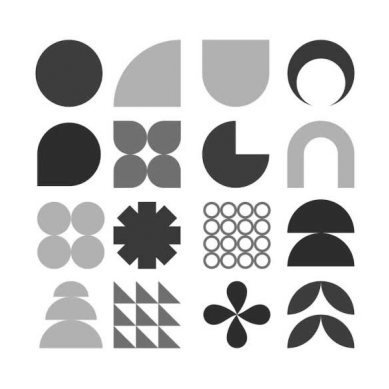

In [6]:
img_path = 'hough.jpg.jpeg'
gray_img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
plt.imshow(gray_img, cmap="gray")
plt.axis("off")
plt.show()

Running on CPU using NumPy/OpenCV


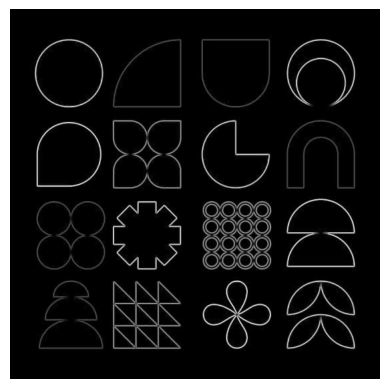

In [7]:
print("Running on CPU using NumPy/OpenCV")

kernel_vert = np.array([[-1, -2, -1],
                        [ 0,  0,  0],
                        [ 1,  2,  1]], dtype=np.float32)
kernel_horiz = kernel_vert.T

img_f32 = gray_img.astype(np.float32)

grad_x = cv2.filter2D(img_f32, -1, kernel_horiz, borderType=cv2.BORDER_REPLICATE)
grad_y = cv2.filter2D(img_f32, -1, kernel_vert, borderType=cv2.BORDER_REPLICATE)

edge_mag = np.hypot(grad_x, grad_y)

plt.imshow(edge_mag, cmap="gray")
plt.axis("off")
plt.show()

In [8]:
img_h, img_w = edge_mag.shape
max_rho = int(np.ceil(np.hypot(img_w, img_h)))
n_theta = 180

acc = np.zeros((2 * max_rho + 1, n_theta), dtype=np.int32)

ys, xs = np.nonzero(edge_mag > 50)
angles = np.deg2rad(np.arange(n_theta, dtype=np.float32))
cos_vals, sin_vals = np.cos(angles), np.sin(angles)
theta_ids = np.arange(n_theta, dtype=np.int64)

# process edge pixels in batches so memory stays under control
batch = 10_000
for i in range(0, xs.size, batch):
    bx = xs[i:i + batch, None]
    by = ys[i:i + batch, None]
    rho_vals = np.rint(bx * cos_vals + by * sin_vals).astype(np.int64) + max_rho
    flat_ids = (rho_vals * n_theta + theta_ids).ravel()
    counts = np.bincount(flat_ids, minlength=acc.size)
    acc += counts.reshape(acc.shape).astype(np.int32)

print("Hough accumulator created successfully on CPU.")

Hough accumulator created successfully on CPU.


Number of detected lines: 10948


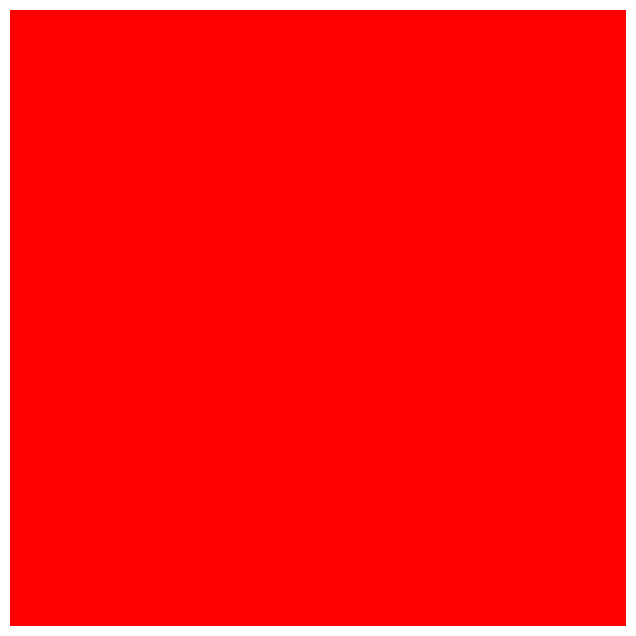

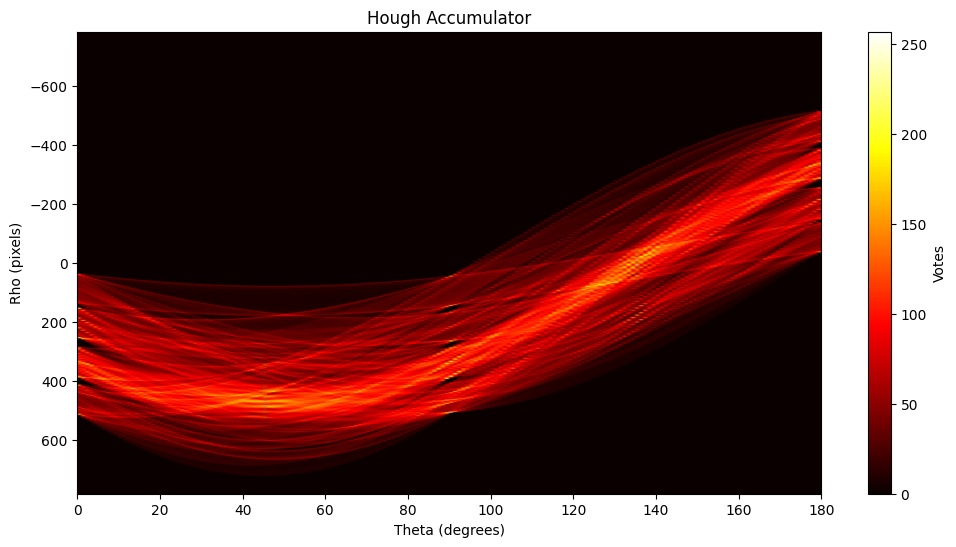

In [9]:
vote_thresh = 100

# accumulator cells with enough votes
rho_ids, theta_ids_found = np.where(acc >= vote_thresh)
detected = [(int(r) - max_rho, np.deg2rad(int(t))) for r, t in zip(rho_ids, theta_ids_found)]

print("Number of detected lines:", len(detected))

# draw detected lines over the edge map
canvas = cv2.cvtColor(edge_mag.astype(np.uint8), cv2.COLOR_GRAY2BGR)
for rho, theta in detected:
    ca, sa = np.cos(theta), np.sin(theta)
    cx, cy = ca * rho, sa * rho
    p1 = (int(cx - 1000 * sa), int(cy + 1000 * ca))
    p2 = (int(cx + 1000 * sa), int(cy - 1000 * ca))
    cv2.line(canvas, p1, p2, (0, 0, 255), 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

# accumulator heatmap
plt.figure(figsize=(12, 6))
plt.imshow(acc, cmap="hot", aspect="auto", extent=[0, 180, max_rho, -max_rho])
plt.xlabel("Theta (degrees)")
plt.ylabel("Rho (pixels)")
plt.title("Hough Accumulator")
plt.colorbar(label="Votes")
plt.show()

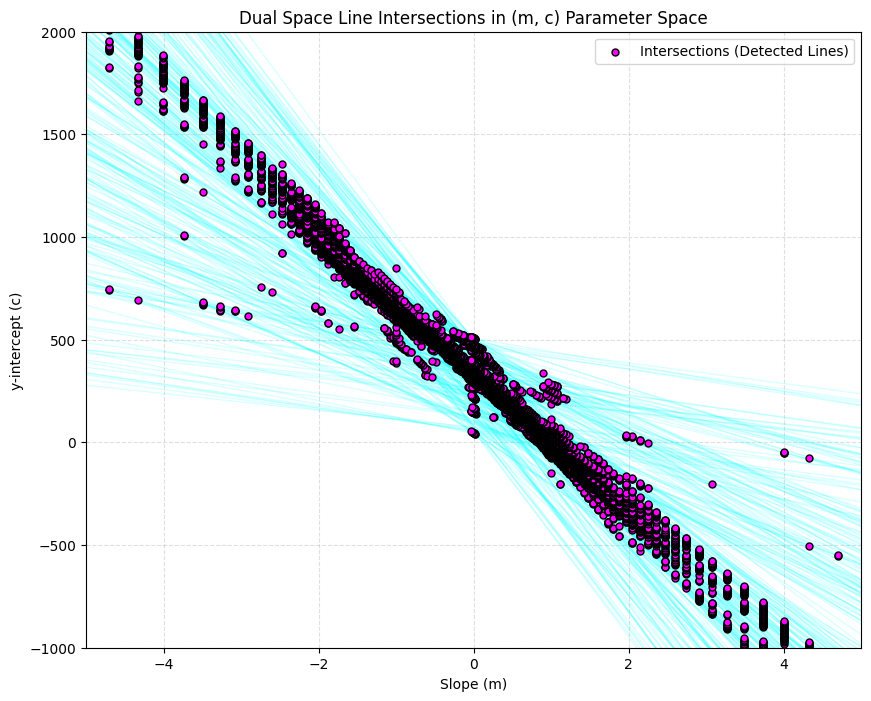

In [11]:
# Each edge point (x, y) becomes the line c = y - m*x in (m, c) space.
# Detected lines (rho, theta) become single points (m, c).
plt.figure(figsize=(10, 8))

ey, ex = np.nonzero(edge_mag > 50)
skip = max(1, len(ex) // 300)
ex_s, ey_s = ex[::skip], ey[::skip]

m_range = np.linspace(-5, 5, 400)
for px, py in zip(ex_s, ey_s):
    plt.plot(m_range, py - m_range * px, color="cyan", alpha=0.15, linewidth=1)

# convert detected (rho, theta) -> (m, c)
m_pts, c_pts = [], []
for rho, theta in detected:
    s = np.sin(theta)
    if abs(s) > 1e-6:
        m_pts.append(-np.cos(theta) / s)
        c_pts.append(rho / s)

plt.scatter(m_pts, c_pts, c="magenta", edgecolors="black", s=25,
            label="Intersections (Detected Lines)", zorder=3)

plt.xlim(-5, 5)
plt.ylim(-1000, 2000)
plt.xlabel("Slope (m)")
plt.ylabel("y-intercept (c)")
plt.title("Dual Space Line Intersections in (m, c) Parameter Space")
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.show()

In [12]:
sorted_idx = np.argsort(acc, axis=None)[::-1]
peak_rhos, peak_thetas = [], []
suppressed = np.zeros_like(acc, dtype=bool)

# non-maximum suppression: skip cells near an already chosen peak
for flat in sorted_idx:
    r, t = np.unravel_index(int(flat), acc.shape)
    r_lo, t_lo = max(0, r - 10), max(0, t - 10)
    if not suppressed[r_lo:r + 10, t_lo:t + 10].any():
        suppressed[r, t] = True
        peak_rhos.append(r - max_rho)
        peak_thetas.append(np.deg2rad(t))
        if len(peak_rhos) == 3:
            break

print("Top 3 Detected Line Parameters:")
for n, (rho, theta) in enumerate(zip(peak_rhos, peak_thetas), start=1):
    s = np.sin(theta)
    if abs(s) > 1e-6:
        slope = -np.cos(theta) / s
        icpt = rho / s
        print(f"Line {n}: y = {slope:.4f}*x + {icpt:.4f} "
              f"(Theta: {np.rad2deg(theta):.1f} deg, Rho: {rho})")
    else:
        print(f"Line {n}: Vertical line (Theta: {np.rad2deg(theta):.1f} deg, Rho: {rho})")

Top 3 Detected Line Parameters:
Line 1: y = 1.0000*x + 11.3137 (Theta: 135.0 deg, Rho: 8)
Line 2: y = -0.0000*x + 506.0000 (Theta: 90.0 deg, Rho: 506)
Line 3: y = 1.0000*x + 63.6396 (Theta: 135.0 deg, Rho: 45)
